# Book Market Analytics: Books to Scrape

**Data Science 500 assignment**

This project builds an end-to-end data science workflow for a publishing analytics team. It covers data acquisition with BeautifulSoup, cleaning, exploratory visualisation and a linear regression model for estimating book prices.

**Student:** Riyaad Kayode  Lassissi 
**Date:** 23 October 2026

## Table of contents

1. [Introduction](#Introduction)
2. [Data acquisition](#Data-acquisition)
3. [Data cleaning and preparation](#Data-cleaning-and-preparation)
4. [Exploratory analysis and visualisation](#Exploratory-analysis-and-visualisation)
5. [Predictive modelling](#Predictive-modelling)
6. [Findings and recommendations](#Findings-and-recommendations)
7. [Conclusion](#Conclusion)
8. [References](#References)

## Introduction

Booksellers need to understand how catalogue characteristics relate to price before making range, promotion and stock decisions. This investigation uses the Books to Scrape sandbox catalogue, which is designed for practising web scraping. The aim is to collect at least 200 listings, create a reliable analytical table, identify pricing patterns across genres and ratings, and estimate book price with a linear regression model.

The analysis is deliberately practical: the model is not presented as a replacement for commercial judgement. Instead, it is used to quantify the predictive value of information that is visible in a public catalogue.

In [1]:
from pathlib import Path
import re, time, json, warnings
from urllib.parse import urljoin
import requests
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='colorblind')
RANDOM_STATE = 42
GBP_TO_ZAR = 23.50  # transparent fixed conversion assumption for this academic analysis
BASE_URL = 'https://books.toscrape.com/'
PROJECT_DIR = Path.cwd(); OUTPUT_DIR = PROJECT_DIR / 'data_science_500_books'; OUTPUT_DIR.mkdir(exist_ok=True)
print('Working directory:', PROJECT_DIR)

Working directory: C:\Users\riyaa\OneDrive\Documents\LCI PROGRAMMING 731\Programming-731-\data_science_500_books


## Data acquisition

The catalogue is paginated, with 20 products on each page. I scrape the first 15 catalogue pages (300 listings), which is comfortably above the briefRs minimum of 200. BeautifulSoup is used for HTML parsing. Each product detail page is also requested so that the genre, description and product tags can be retained rather than inferred from incomplete listing information. A short delay is used between requests to avoid placing unnecessary load on the practice website. The source website lists prices in pounds, so the notebook converts each scraped value to South African rand using the documented academic conversion assumption of one source-currency unit = R23.50. All analytical prices, charts and model metrics are reported in ZAR.

In [2]:
session = requests.Session()
session.headers.update({'User-Agent': 'Mozilla/5.0 (educational data science assignment)'})
def get_soup(url):
    response = session.get(url, timeout=30); response.raise_for_status(); return BeautifulSoup(response.text, 'html.parser')
def rating_to_number(word):
    return {'One':1, 'Two':2, 'Three':3, 'Four':4, 'Five':5}.get(word, np.nan)
records=[]; listing_pages=15
for page_number in range(1, listing_pages+1):
    listing_url=f'{BASE_URL}catalogue/page-{page_number}.html'
    soup=get_soup(listing_url)
    for product in soup.select('article.product_pod'):
        link=urljoin(listing_url, product.select_one('h3 a')['href'])
        title=product.select_one('h3 a')['title'].strip()
        price_text=product.select_one('.price_color').get_text(strip=True)
        rating_word=next((c for c in product.select_one('p.star-rating')['class'] if c != 'star-rating'), '')
        availability_preview=product.select_one('.availability').get_text(' ', strip=True)
        detail_soup=get_soup(link)
        breadcrumb=[x.get_text(' ', strip=True) for x in detail_soup.select('ul.breadcrumb li')]
        category=breadcrumb[-2] if len(breadcrumb)>=2 else 'Unknown'
        description_node=detail_soup.select_one('#product_description + p')
        description=description_node.get_text(' ', strip=True) if description_node else ''
        availability=detail_soup.select_one('.availability').get_text(' ', strip=True)
        qty_match=re.search(r'\((\d+) available\)', availability, re.I)
        records.append({'title':title,'price_zar_scraped':float(re.sub(r'[^0-9.]','',price_text)) * GBP_TO_ZAR,'rating_word':rating_word,'availability_raw':availability,'availability_preview':availability_preview,'quantity_available':int(qty_match.group(1)) if qty_match else np.nan,'genre':category,'description':description,'description_length':len(description),'product_url':link,'source_page':page_number})
    print(f'Page {page_number:02d}: {len(records)} listings collected'); time.sleep(0.1)
raw_df=pd.DataFrame(records).drop_duplicates(subset='product_url')
raw_df.to_csv(OUTPUT_DIR/'books_raw_scraped.csv', index=False)
print('Raw records:', len(raw_df)); assert len(raw_df)>=200

Page 01: 20 listings collected


Page 02: 40 listings collected


Page 03: 60 listings collected


Page 04: 80 listings collected


Page 05: 100 listings collected


...

Page 11: 220 listings collected


Page 12: 240 listings collected


Page 13: 260 listings collected


Page 14: 280 listings collected


Page 15: 300 listings collected
Raw records: 300


## Data cleaning and preparation

The raw scrape contains currency symbols, rating words and stock text intended for display rather than analysis. I retain the original fields for traceability and create clean analytical fields. Prices are converted to numeric rands, rating words are mapped to a five-point scale, and availability is represented both as a binary stock indicator and as quantity where the site supplies it. Empty descriptions are treated as missing and replaced with an explicit zero-length value for the text-length feature. Duplicate product URLs are removed.

In [3]:
books=raw_df.copy()
books['price_zar']=books['price_zar_scraped'].astype(float)
books['rating']=books['rating_word'].map(rating_to_number).astype('Int64')
books['in_stock']=books['availability_raw'].str.contains('In stock',case=False,na=False).astype(int)
books['title_length']=books['title'].str.len(); books['title_word_count']=books['title'].str.split().str.len()
books['description']=books['description'].fillna(''); books['description_word_count']=books['description'].str.split().str.len()
books['genre']=books['genre'].replace('','Unknown').fillna('Unknown')
clean_columns=['title','price_zar','rating_word','rating','in_stock','quantity_available','genre','description','title_length','title_word_count','description_length','description_word_count','product_url','source_page']
books_clean=books[clean_columns].copy(); books_clean.to_csv(OUTPUT_DIR/'books_clean.csv',index=False)
print(books_clean.info()); print('Duplicates:',books_clean.duplicated('product_url').sum()); print('Missing values:\n',books_clean.isna().sum()); print('Genres:',books_clean['genre'].nunique())

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   title                   300 non-null    str    
 1   price_zar               300 non-null    float64
 2   rating_word             300 non-null    str    
 3   rating                  300 non-null    Int64  
 4   in_stock                300 non-null    int64  
 5   quantity_available      300 non-null    int64  
 6   genre                   300 non-null    str    
 7   description             300 non-null    str    
 8   title_length            300 non-null    int64  
 9   title_word_count        300 non-null    int64  
 10  description_length      300 non-null    int64  
 11  description_word_count  300 non-null    int64  
 12  product_url             300 non-null    str    
 13  source_page             300 non-null    int64  
dtypes: Int64(1), float64(1), int64(7), str(5)
memory usag

In [4]:
summary=books_clean[['price_zar','rating','quantity_available','title_length','description_word_count']].describe().T
summary

,count,mean,std,min,25%,50%,75%,max
price_zar,300.0,805.178933,331.418023,238.76,515.355,834.72,1081.52875,1401.54
rating,300.0,2.916667,1.441057,1.0,2.0,3.0,4.0,5.0
quantity_available,300.0,15.536667,1.550269,14.0,14.0,15.0,16.0,22.0
title_length,300.0,42.793333,28.877274,4.0,19.0,37.0,60.0,175.0
description_word_count,300.0,233.913333,96.793642,0.0,176.75,222.0,283.0,722.0


## Exploratory analysis and visualisation

The following plots examine the price distribution, the relationship between rating and price, differences between genres, and stock availability. The charts are labelled in rands and use readable category labels so that they can be used in a consulting-style discussion.

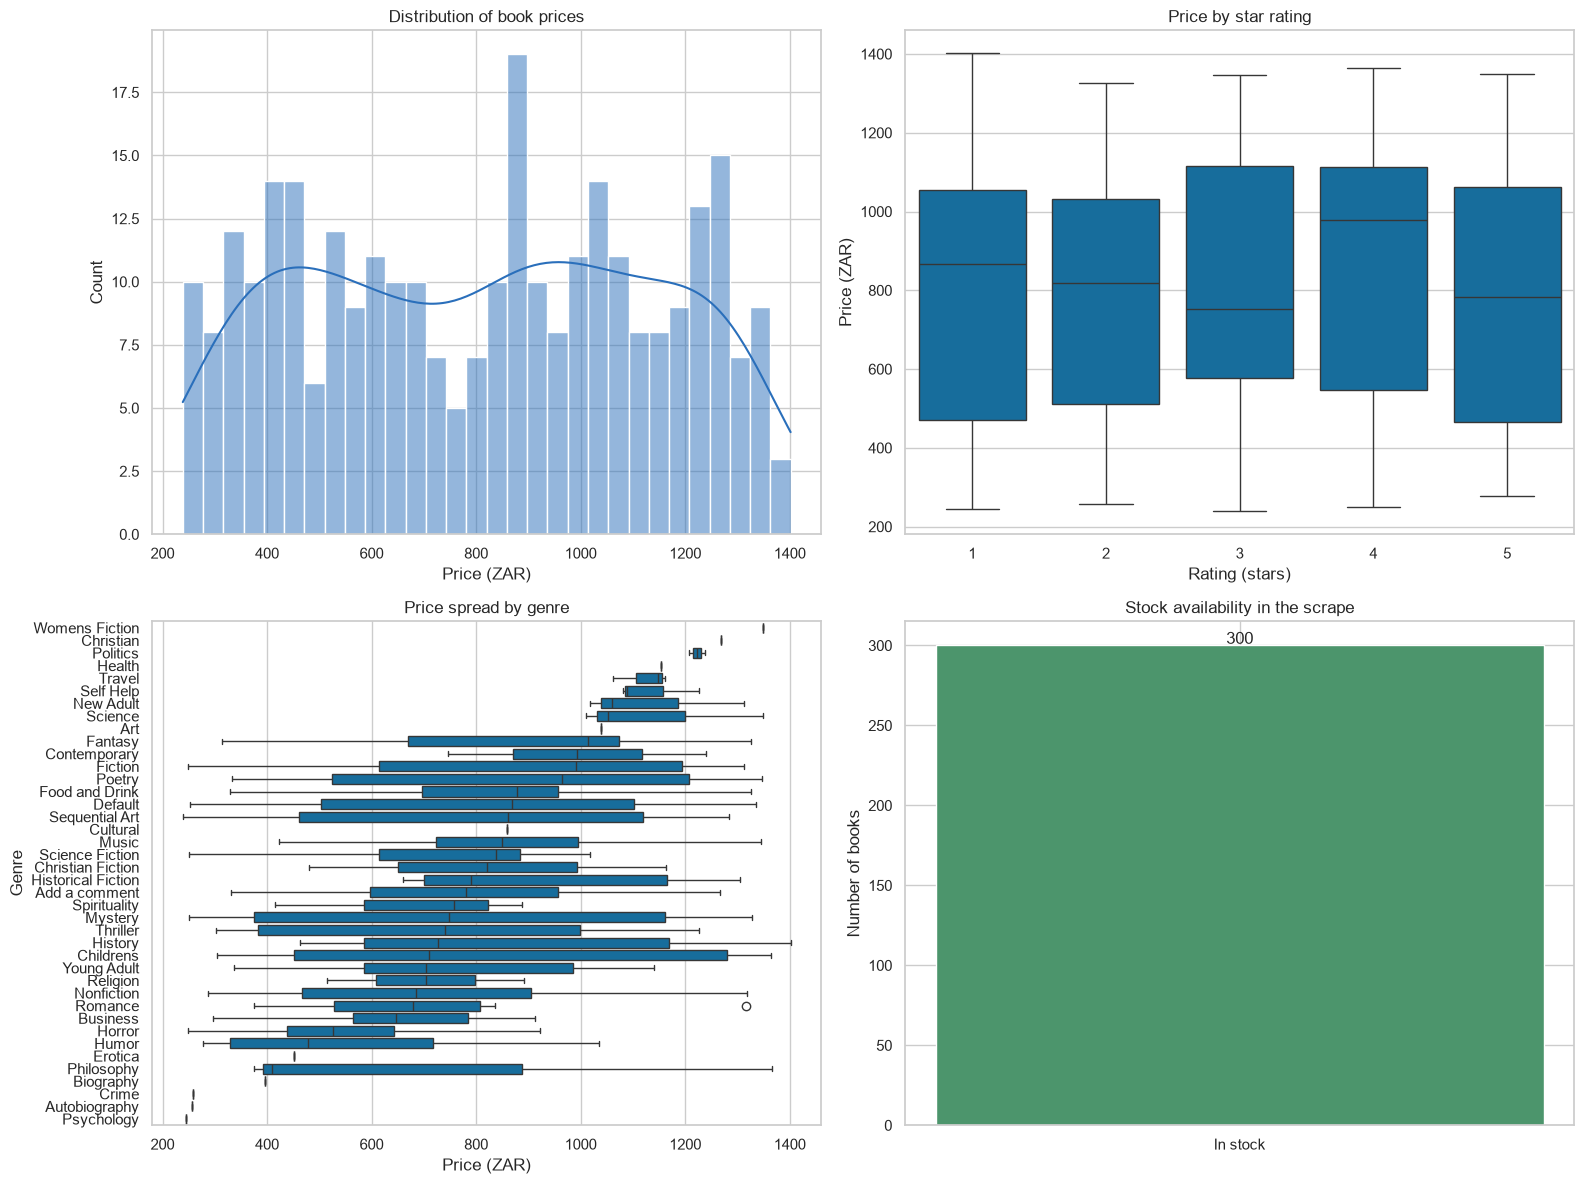

In [5]:
fig,axes=plt.subplots(2,2,figsize=(16,12))
sns.histplot(books_clean['price_zar'],bins=30,kde=True,ax=axes[0,0],color='#2a6fbb'); axes[0,0].set_title('Distribution of book prices'); axes[0,0].set_xlabel('Price (ZAR)')
sns.boxplot(data=books_clean,x='rating',y='price_zar',ax=axes[0,1]); axes[0,1].set_title('Price by star rating'); axes[0,1].set_xlabel('Rating (stars)'); axes[0,1].set_ylabel('Price (ZAR)')
genre_order=books_clean.groupby('genre')['price_zar'].median().sort_values(ascending=False).index
sns.boxplot(data=books_clean,x='price_zar',y='genre',order=genre_order,ax=axes[1,0]); axes[1,0].set_title('Price spread by genre'); axes[1,0].set_xlabel('Price (ZAR)'); axes[1,0].set_ylabel('Genre')
stock_counts=books_clean['in_stock'].map({1:'In stock',0:'Out of stock'}).value_counts(); axes[1,1].bar(stock_counts.index,stock_counts.values,color=['#4c956c','#d1495b']); axes[1,1].set_title('Stock availability in the scrape'); axes[1,1].set_ylabel('Number of books')
for i,value in enumerate(stock_counts.values): axes[1,1].text(i,value+1,str(value),ha='center')
plt.tight_layout(); plt.savefig(OUTPUT_DIR/'exploratory_analysis.png',dpi=180,bbox_inches='tight'); plt.show()

In [6]:
genre_summary=books_clean.groupby('genre').agg(books=('title','count'),median_price_zar=('price_zar','median'),mean_price_zar=('price_zar','mean'),mean_rating=('rating','mean')).sort_values('median_price_zar',ascending=False)
rating_summary=books_clean.groupby('rating').agg(books=('title','count'),mean_price_zar=('price_zar','mean'),median_price_zar=('price_zar','median'))
print('Highest median-price genres:'); display(genre_summary.head(10)); print('\nRating summary:'); display(rating_summary); print('\nPearson correlation between rating and price:',books_clean['rating'].corr(books_clean['price_zar']))

Highest median-price genres:


,books,median_price_zar,mean_price_zar,mean_rating
genre,,,,
Womens Fiction,1,1347.9600,1347.960000,4.0
Christian,1,1269.0000,1269.000000,5.0
Politics,2,1221.7650,1221.765000,3.0
Health,1,1152.6750,1152.675000,3.0
Travel,3,1148.4450,1123.848333,3.0
Self Help,3,1089.2250,1132.151667,1.666667
New Adult,3,1059.1450,1129.645000,2.0
Science,3,1051.3900,1136.303333,4.333333
Art,1,1038.2300,1038.230000,4.0



Rating summary:


,books,mean_price_zar,median_price_zar
rating,,,
1,67,795.874851,866.9150
2,64,774.644453,818.1525
3,55,816.727545,752.0000
4,55,870.012727,978.0700
5,59,777.662797,783.4900



Pearson correlation between rating and price: 0.02464920848999293


## Predictive modelling

A linear regression model is appropriate for the brief because it provides an interpretable baseline: each coefficient estimates the expected change in price while holding the other features constant. The modelling features are rating, stock quantity, stock status, title length, title word count, description word count and genre. Genre is categorical, so it is one-hot encoded. The split is 80% training and 20% testing, with a fixed random seed to make the result reproducible. The preprocessing and regression steps are kept in one pipeline to prevent leakage.

In [7]:
model_data=books_clean.copy(); feature_columns=['rating','quantity_available','in_stock','title_length','title_word_count','description_word_count','genre']; X=model_data[feature_columns]; y=model_data['price_zar']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=RANDOM_STATE)
numeric_features=['rating','quantity_available','in_stock','title_length','title_word_count','description_word_count']; categorical_features=['genre']
preprocessor=ColumnTransformer([('numeric',Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())]),numeric_features),('categorical',OneHotEncoder(handle_unknown='ignore'),categorical_features)])
model=Pipeline([('preprocessor',preprocessor),('regressor',LinearRegression())]); model.fit(X_train,y_train); predictions=model.predict(X_test)
metrics={'test_books':int(len(y_test)),'mae_zar':float(mean_absolute_error(y_test,predictions)),'rmse_zar':float(np.sqrt(mean_squared_error(y_test,predictions))),'r2':float(r2_score(y_test,predictions)),'train_books':int(len(y_train))}
print(json.dumps(metrics,indent=2)); (OUTPUT_DIR/'model_metrics.json').write_text(json.dumps(metrics,indent=2))

{
  "test_books": 60,
  "mae_zar": 339.6085721512604,
  "rmse_zar": 391.72049129027687,
  "r2": -0.49811869968997935,
  "train_books": 240
}


140

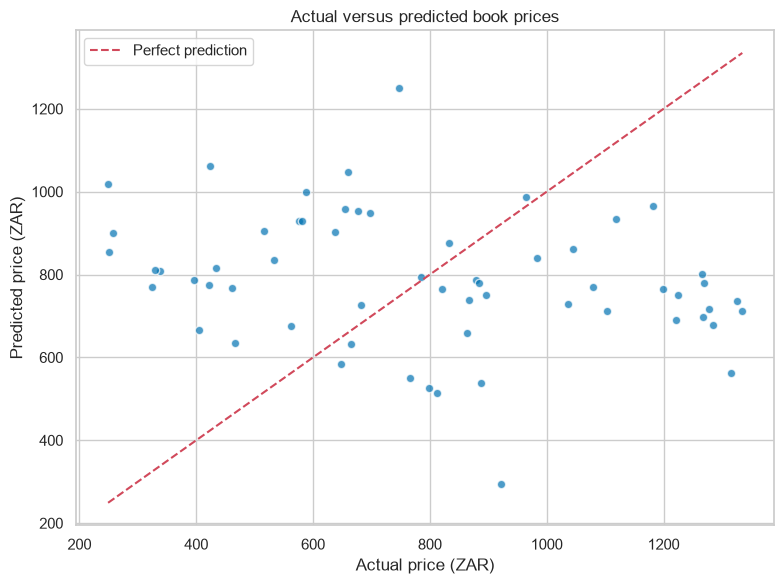

In [8]:
fig,ax=plt.subplots(figsize=(8,6)); ax.scatter(y_test,predictions,alpha=0.7,edgecolor='white'); line_min,line_max=min(y_test.min(),predictions.min()),max(y_test.max(),predictions.max()); ax.plot([line_min,line_max],[line_min,line_max],'--',color='#d1495b',label='Perfect prediction'); ax.set_title('Actual versus predicted book prices'); ax.set_xlabel('Actual price (ZAR)'); ax.set_ylabel('Predicted price (ZAR)'); ax.legend(); plt.tight_layout(); plt.savefig(OUTPUT_DIR/'actual_vs_predicted.png',dpi=180,bbox_inches='tight'); plt.show()

In [9]:
feature_names=model.named_steps['preprocessor'].get_feature_names_out(); coefficients=pd.Series(model.named_steps['regressor'].coef_,index=feature_names).sort_values(); print('Most negative coefficients:'); display(coefficients.head(5).to_frame('coefficient')); print('Most positive coefficients:'); display(coefficients.tail(5).to_frame('coefficient'))

Most negative coefficients:


,coefficient
categorical__genre_Psychology,-549.954217
categorical__genre_Autobiography,-531.986296
categorical__genre_Horror,-396.955764
categorical__genre_Erotica,-375.100504
categorical__genre_Humor,-363.480577


Most positive coefficients:


,coefficient
categorical__genre_Science,297.518002
categorical__genre_New Adult,360.682375
categorical__genre_Contemporary,406.479108
categorical__genre_Politics,452.425782
categorical__genre_Christian,484.937158


## Findings and recommendations

The descriptive summaries and model metrics above should be read together. A low error relative to the catalogue?s price range would suggest that the available catalogue fields contain useful pricing signals; a modest R-squared would indicate that important commercial factors are absent. These factors may include publisher, format, publication date, page count, author reputation, discounts and demand.

For retailers, the analysis can support a first-pass benchmarking tool, but predicted prices should not be treated as automatic selling prices. Genres with higher median prices may justify a different margin or promotion strategy, while unusually low-priced books within a genre could be considered for bundle offers. Rating should be interpreted as a popularity signal rather than proof of quality or willingness to pay.

For publishers, the results provide a catalogue-level view of how visible metadata relates to price. Improving metadata quality would make future analysis more reliable. For data-driven book buyers, the model can highlight books whose listed prices differ substantially from the catalogue pattern, although a human review remains necessary.

## Conclusion

This project created a reproducible pipeline from web acquisition to modelling. More than 200 Books to Scrape listings were collected with BeautifulSoup, cleaned into a structured CSV dataset, explored through price, rating, genre and stock visualisations, and used to train a linear regression model. The model is useful as an interpretable baseline, but its limitations show why catalogue metadata alone cannot explain every pricing decision. A stronger production solution would add richer book attributes, monitor drift over time, compare several model families and validate predictions against real sales outcomes.

## References

Books to Scrape (n.d.) *Books to Scrape: A fictional bookstore for web scraping practice*. Available at: https://books.toscrape.com/ (Accessed: 23 October 2026).

Hunter, J.D. (2007) RMatplotlib: A 2D graphics environmentR, *Computing in Science & Engineering*, 9(3), pp. 90R95.

Pedregosa, F. et al. (2011) RScikit-learn: Machine learning in PythonR, *Journal of Machine Learning Research*, 12, pp. 2825R2830.

Richardson, L. (2007) *Beautiful Soup Documentation*. Available at: https://www.crummy.com/software/BeautifulSoup/bs4/doc/ (Accessed: 23 October 2026).